# plagiarism_v2 — просмотр сэмплов аугментаций

Ноутбук показывает пары «оригинал | аугментация» для словаря v2 и проверяет правила совместимости.
Запускать из `plagiarism_v2/notebooks/` (пути как в остальных ноутбуках репозитория).

Разделы:
1. случайные последовательности при заданном `p`;
2. новые токены по отдельности: `jpeg_artefacts`, `text_overlay`, `fragment_edit`;
3. макеты текста и языки;
4. подвиды `fragment_edit`;
5. проверка правил: `jpeg ∧ noise`, `text ∧ fragment`, статистика.

In [1]:
import sys
sys.path.insert(0, '../')
sys.path.insert(0, '../../')

import os, random
from collections import Counter
from contextlib import contextmanager

import matplotlib.pyplot as plt
from PIL import Image

from plagiarism_v2.dataset_v2 import ImageTransformerV2, FRAGMENT_KINDS, TEXT_LAYOUTS, TRANSFORM_TOKENS_V2
from plagiarism_v2.dataset_v2.overlays import RAQM_AVAILABLE

%load_ext autoreload
%autoreload 2

## Настройки

In [2]:
IMAGES_DIR = '../../assets'          # папка с картинками для просмотра (лучше реальные фото)
STICKER_DIR = '../assets/stickers'   # PNG-стикеры с альфой, можно пустую
TEXT_CORPUS_DIR = None               # папка с *.txt для дополнительного текста, можно None
P = 0.3                              # вероятность токена (как initial_p в конфиге)
SEED = 0

random.seed(SEED)

tr = ImageTransformerV2(sticker_dir=STICKER_DIR, text_corpus_dir=TEXT_CORPUS_DIR)

print('vocab:', TRANSFORM_TOKENS_V2)
print('tokens sampled:', tr.transformations)
print('fragment kinds:', dict(tr.fragment_editor.kind_weights))
print('text languages:', tr.text_langs, '| raqm:', RAQM_AVAILABLE)
print('fonts:', len(tr.font_bank.paths), '| sticker assets:', len(tr.fragment_editor.sticker_bank.paths))
print('exclusive groups:', [sorted(g) for g in tr.exclusive_groups])


vocab: {'[PAD]': 0, '[START]': 1, '[END]': 2, 'noop': 3, 'grayscale': 4, 'rotate_90': 5, 'rotate_180': 6, 'rotate_270': 7, 'color_jitter': 8, 'noise_adding': 9, 'crop': 10, 'horizontal_flip': 11, 'vertical_flip': 12, 'jpeg_artefacts': 13, 'text_overlay': 14, 'fragment_edit': 15}
tokens sampled: ['noop', 'grayscale', 'rotate_90', 'rotate_180', 'rotate_270', 'color_jitter', 'noise_adding', 'crop', 'horizontal_flip', 'vertical_flip', 'jpeg_artefacts', 'text_overlay', 'fragment_edit']
fragment kinds: {'sticker': 2.0, 'annotation': 2.0, 'blur_censor': 1.0, 'pixelate_censor': 1.0, 'black_box': 1.0, 'copy_move': 1.5, 'inpaint_fill': 1.5, 'recolor': 1.0}
text languages: ['ar', 'de', 'en', 'es', 'fr', 'it', 'pl', 'pt', 'ru', 'tr', 'uk'] | raqm: True
fonts: 6 | sticker assets: 0
exclusive groups: [['jpeg_artefacts', 'noise_adding'], ['fragment_edit', 'text_overlay']]


## Вспомогательные функции

In [3]:
def list_images(folder):
    paths = [os.path.join(folder, f) for f in sorted(os.listdir(folder))
             if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]
    assert paths, f'no images in {folder}'
    return paths

IMAGES = list_images(IMAGES_DIR)
print(len(IMAGES), 'images')


def pick_image(i=None):
    path = IMAGES[i % len(IMAGES)] if i is not None else random.choice(IMAGES)
    return Image.open(path).convert('RGB'), os.path.basename(path)


def details():
    d = list(tr.last_fragment_kinds)
    if tr.last_text_detail:
        d.append('text:' + tr.last_text_detail)
    return d


def show_pairs(rows, cols=2, size=4.2):
    """rows: list of (orig, aug, title)."""
    n = len(rows)
    ncols = cols * 2
    nrows = (n + cols - 1) // cols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 0.8), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for i, (orig, aug, title) in enumerate(rows):
        r, c = divmod(i, cols)
        axes[r, 2 * c].imshow(orig); axes[r, 2 * c].set_title('original', fontsize=9)
        axes[r, 2 * c + 1].imshow(aug); axes[r, 2 * c + 1].set_title(title, fontsize=9, wrap=True)
    plt.tight_layout()
    plt.show()


@contextmanager
def forced_lang(lang):
    """Temporarily restrict the text bank to one language."""
    tb = tr.fragment_editor.text_bank
    saved = dict(tb.lang_weights)
    tb.lang_weights = {lang: 1.0}
    try:
        yield
    finally:
        tb.lang_weights = saved

2 images


## 1. Случайные последовательности

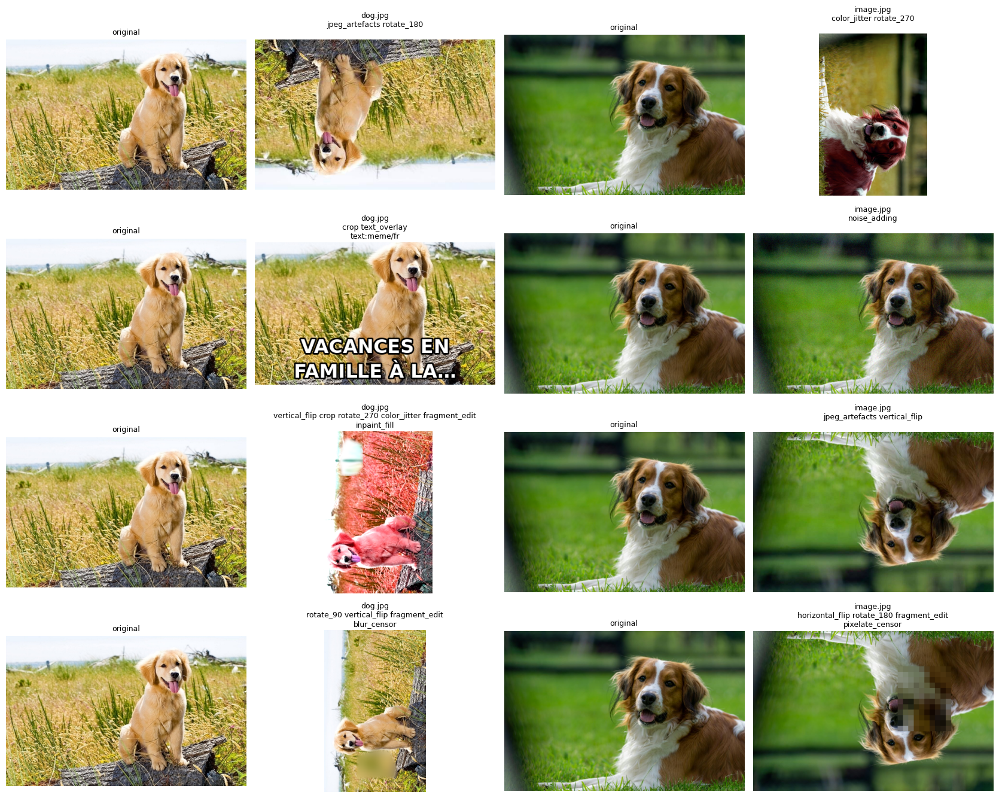

In [4]:
rows = []
for i in range(8):
    img, name = pick_image(i)
    aug, seq = tr.transform(img, p=P)
    rows.append((img, aug, f"{name}\n{' '.join(seq)}\n{', '.join(details())}"))
show_pairs(rows)

## 2. Новые токены по отдельности

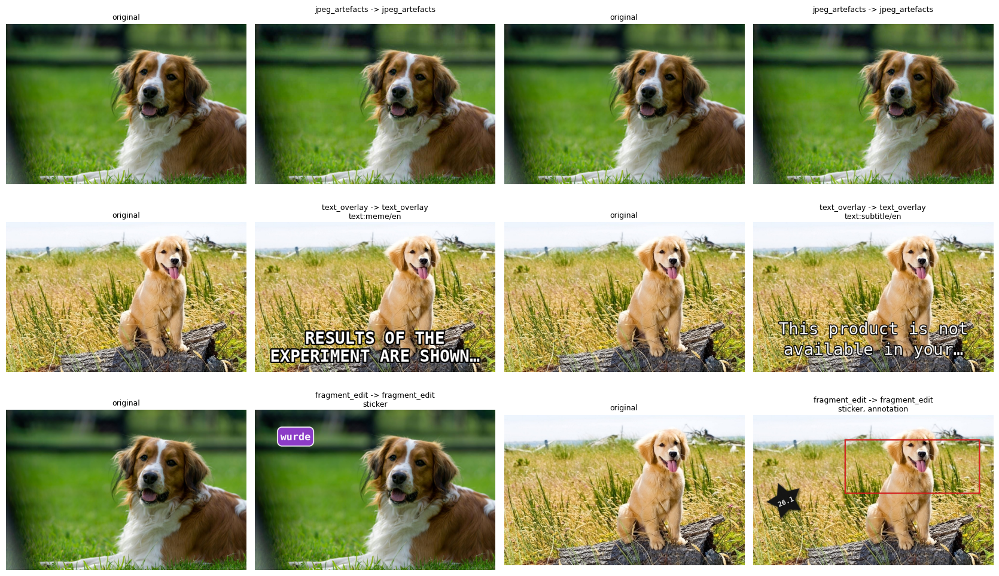

In [5]:
rows = []
for tok in ['jpeg_artefacts', 'text_overlay', 'fragment_edit']:
    for i in range(2):
        img, name = pick_image()
        aug, seq = tr._apply_sequence(img, [tok])
        rows.append((img, aug, f"{tok} -> {' '.join(seq)}\n{', '.join(details())}"))
show_pairs(rows)

## 3a. Макеты текста (`text_overlay`)

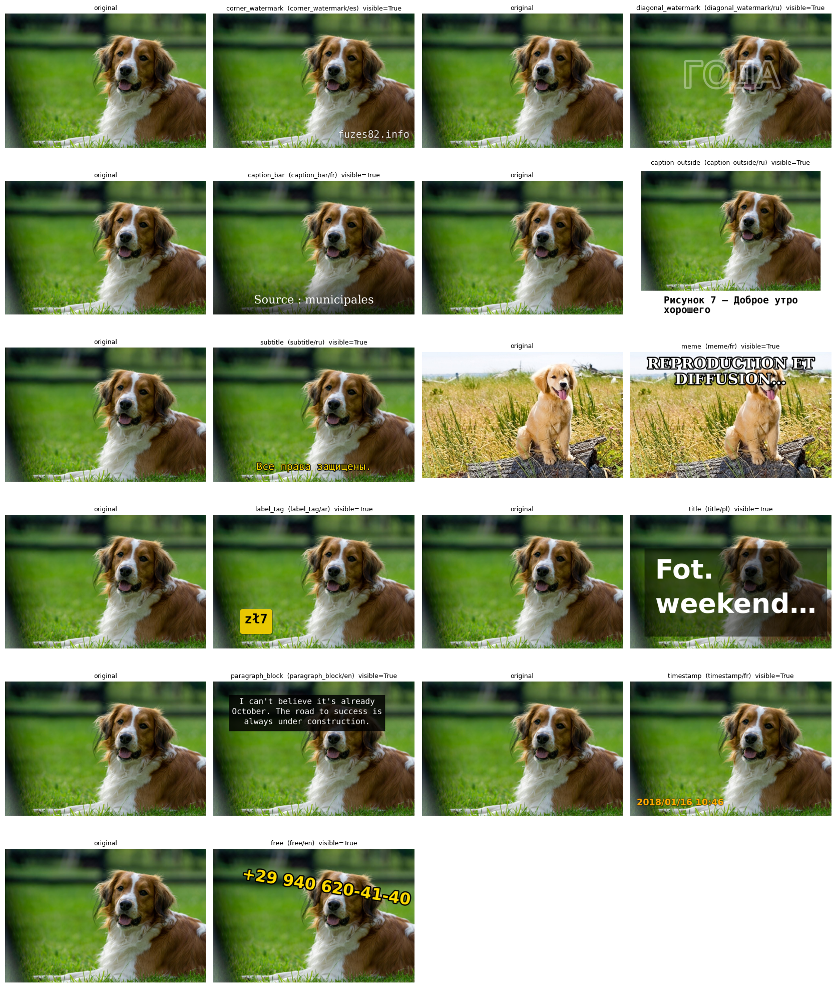

In [6]:
rows = []
for layout in TEXT_LAYOUTS:
    img, name = pick_image()
    aug, ok = tr._apply_text_overlay(img, layout=layout)
    rows.append((img, aug, f"{layout}  ({tr.last_text_detail})  visible={ok}"))
show_pairs(rows)

## 3b. Языки текста

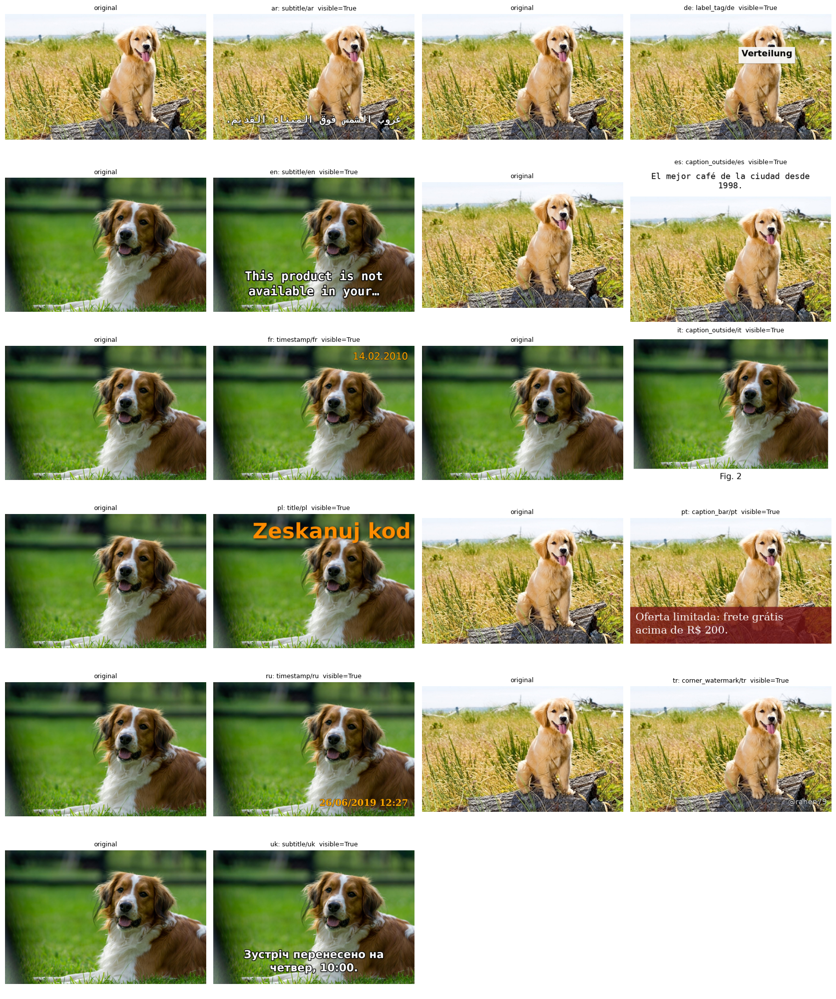

In [7]:
rows = []
for lang in tr.text_langs:
    with forced_lang(lang):
        img, name = pick_image()
        aug, ok = tr._apply_text_overlay(img)
    rows.append((img, aug, f"{lang}: {tr.last_text_detail}  visible={ok}"))
show_pairs(rows)

## 4. Подвиды `fragment_edit`

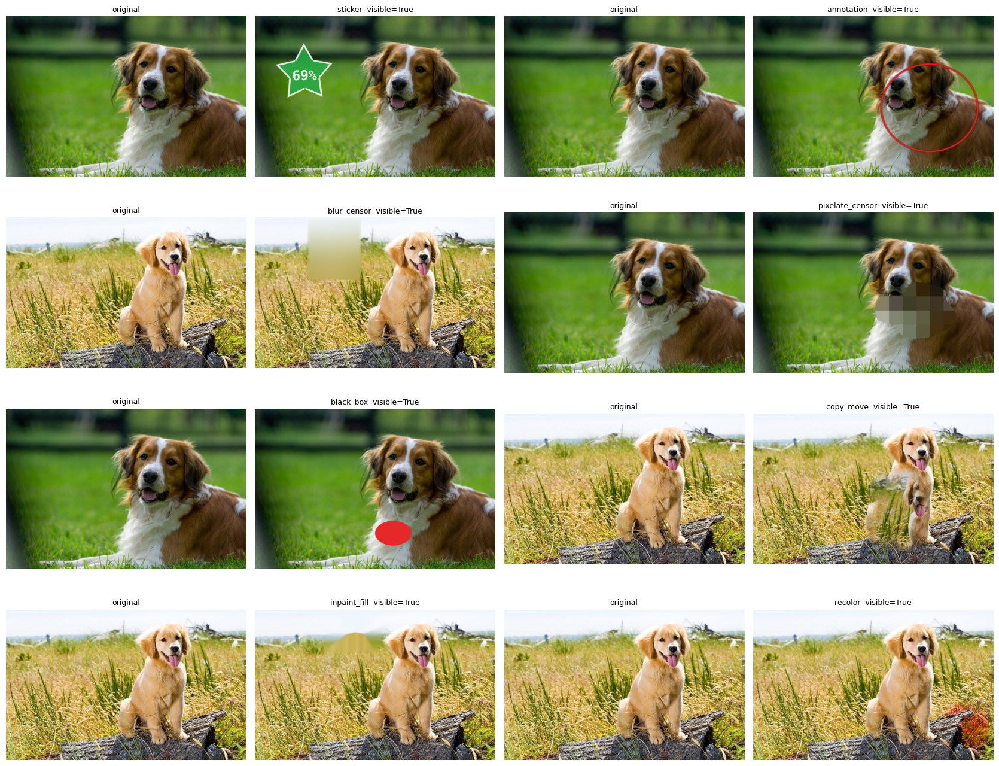

In [8]:
rows = []
for kind in FRAGMENT_KINDS:
    img, name = pick_image()
    aug, ok = tr._apply_fragment_edit(img, kinds=[kind])
    rows.append((img, aug, f"{kind}  visible={ok}"))
show_pairs(rows)

## 5. Проверка правил

* не более одного из `{jpeg_artefacts, noise_adding}` и одного из `{text_overlay, fragment_edit}`;
* порядок применения случайный, как в v1.

In [9]:
N = 500
tok_counter, kind_counter, layout_counter, lang_counter, lengths = Counter(), Counter(), Counter(), Counter(), Counter()
dropped = Counter()
violations = []

for j in range(N):
    img, _ = pick_image(j)
    sampled = tr.sample_transformations(img, P)
    aug, seq = tr._apply_sequence(img, sampled)
    for g in tr.exclusive_groups:
        if sum(t in g for t in seq) > 1:
            violations.append(('exclusive', seq))
    if len(set(tr.last_fragment_kinds)) != len(tr.last_fragment_kinds):
        violations.append(('dup_kind', tr.last_fragment_kinds))
    for t in ('text_overlay', 'fragment_edit'):
        if t in sampled and t not in seq:
            dropped[t] += 1
    tok_counter.update(seq)
    kind_counter.update(tr.last_fragment_kinds)
    if tr.last_text_detail:
        layout, lang = tr.last_text_detail.split('/')
        layout_counter[layout] += 1
        lang_counter[lang] += 1
    lengths[len([t for t in seq if t != 'noop'])] += 1

print('violations:', violations[:10], '| total:', len(violations))
print()
print(f'token frequency over {N} samples at p={P}:')
for tok, cnt in tok_counter.most_common():
    print(f'  {tok:16s} {cnt / N:6.3f}')
print('fragment kinds:', dict(kind_counter.most_common()))
print('text layouts:', dict(layout_counter.most_common()))
print('text languages:', dict(lang_counter.most_common()))
print('sequence length distribution:', dict(sorted(lengths.items())))
print('dropped by visibility check:', dict(dropped))

violations: [] | total: 0

token frequency over 500 samples at p=0.3:
  grayscale         0.328
  horizontal_flip   0.310
  vertical_flip     0.298
  crop              0.290
  jpeg_artefacts    0.280
  text_overlay      0.266
  color_jitter      0.266
  noise_adding      0.250
  rotate_180        0.244
  fragment_edit     0.234
  rotate_90         0.206
  rotate_270        0.202
  noop              0.012
fragment kinds: {'sticker': 33, 'annotation': 30, 'inpaint_fill': 26, 'black_box': 20, 'copy_move': 16, 'recolor': 15, 'pixelate_censor': 10, 'blur_censor': 9}
text layouts: {'caption_outside': 19, 'title': 17, 'meme': 16, 'subtitle': 12, 'paragraph_block': 11, 'diagonal_watermark': 11, 'label_tag': 11, 'free': 10, 'corner_watermark': 9, 'caption_bar': 9, 'timestamp': 8}
text languages: {'en': 32, 'ru': 30, 'fr': 11, 'de': 10, 'es': 10, 'it': 9, 'pl': 7, 'tr': 7, 'ar': 7, 'pt': 6, 'uk': 4}
sequence length distribution: {0: 6, 1: 43, 2: 110, 3: 139, 4: 121, 5: 66, 6: 12, 7: 3}
dropped b